In [10]:
import csv

In [5]:
from datasets import load_dataset

# Login using e.g. `huggingface-cli login` to access this dataset
ds = load_dataset("DEEL-AI/NOTAM")

In [7]:
label_list = ds["train"].features["label"].names
print(label_list)

['Airspaces', 'Communication_and_Radar', 'GPS', 'Landing_Navaids', 'Obstacles', 'Parking', 'Procedure', 'Runway', 'Services_and_Facilities', 'Signs_and_Lights', 'Taxiway', 'Terminal_or_Enroute_Navaids', 'Wildlife']


In [ ]:
with open("../outputs/label_list.csv", "w") as file:
    writer = csv.writer(file)
    writer.writerow(label_list)

In [9]:
train_df = ds["train"].to_pandas()
test_df = ds["test"].to_pandas()

In [10]:
train_df.to_csv("../data/raw/train_data.csv", index = False)
test_df.to_csv("../data/raw/test_data.csv", index = False)

In [12]:
print("Training data shape:", train_df.shape)
print("Test data shape:", test_df.shape)
print("\nFirst few rows of training data:")
train_df.head()

Training data shape: (4237, 2)
Test data shape: (4241, 2)

First few rows of training data:


,text,label
0,ILS IJB RWY 15 U/S,3
1,"REF AIP SUP 071/19 ITEM 1,3,4(CHANGE TO READ)\...",3
2,RWY 12L ILS GP U/S,3
3,ILS/DME ICSR FREQ 109.7 MHZ/CH34X NOT AVBL DUE...,3
4,ILS LLZ RWY 12R FREQ 111.1 MHZ U/S,3


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re

In [14]:
df_train = pd.read_csv("../data/raw/train_data.csv")
df.head(10)

,text,label
0,ILS IJB RWY 15 U/S,3
1,"REF AIP SUP 071/19 ITEM 1,3,4(CHANGE TO READ)\...",3
2,RWY 12L ILS GP U/S,3
3,ILS/DME ICSR FREQ 109.7 MHZ/CH34X NOT AVBL DUE...,3
4,ILS LLZ RWY 12R FREQ 111.1 MHZ U/S,3
5,ILS RWY 09 U/S.,3
6,ILS/DME CH38X U/S DUE TO MAINT,3
7,"ILS-LOC,GP,DME FOR RWY 19L-U/S DUE TO FLTCK",3
8,ILS 'IAM' 110.7 RWY15 NOT AVBL DUE MAINT\nEXC ...,3
9,ILS RWY 35 LOC/DME/GP U/S,3


In [15]:
df_train.dtypes

text       str
label    int64
dtype: object

In [16]:
df_train.columns

Index(['text', 'label'], dtype='str')

In [17]:
df_train["label"].value_counts()

label
3     779
0     529
7     415
10    368
4     339
2     332
8     235
1     223
6     216
9     204
5     201
12    199
11    197
Name: count, dtype: int64

In [18]:
print("Number of training rows", len(df_train))

Number of training rows 4237


In [19]:
for c in df_train.columns:
    print(c, df_train[c].iloc[5])

text ILS RWY 09 U/S.
label 3


In [20]:
df_train.isnull().sum()

text     0
label    0
dtype: int64

In [ ]:
plt.figure(figsize = (5, 5))
plt.bar(df_train["label"], height = )
plt.show()

TypeError: bar() missing 1 required positional argument: 'height'

<Figure size 500x500 with 0 Axes>

In [22]:
df_train["text"].str.len().describe()

count    4237.000000
mean      125.990795
std       183.897698
min         7.000000
25%        36.000000
50%        71.000000
75%       142.000000
max      2303.000000
Name: text, dtype: float64

In [23]:
df_train['text'].str.split().str.len().describe()

count    4237.000000
mean       20.931319
std        31.834147
min         2.000000
25%         7.000000
50%        12.000000
75%        24.000000
max       563.000000
Name: text, dtype: float64

In [24]:
df_train["text"].str.len()

0        18
1       642
2        18
3       112
4        34
       ... 
4232     39
4233     55
4234     28
4235    152
4236     22
Name: text, Length: 4237, dtype: int64

The text distribution matters for the model's context window

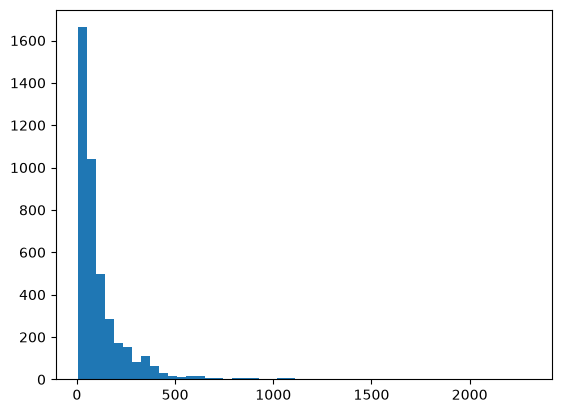

In [25]:
# histogram
plt.hist(df_train["text"].str.len(), bins = 50)

plt.show()

In [26]:
df_train["text"].str.split().str.len()

0        5
1       73
2        5
3       20
4        8
        ..
4232     7
4233    10
4234     6
4235    25
4236     5
Name: text, Length: 4237, dtype: int64

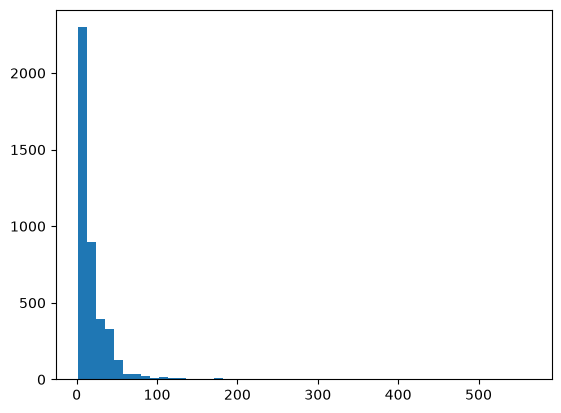

In [28]:
plt.hist(df_train["text"].str.split().str.len(), bins = 50)
plt.show()